<a href="https://colab.research.google.com/github/geyerfranziska/DataScience/blob/main/colab/exercise_03/learning-from-data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Learning from Data

## Warmup

To warm up, you will define the weights of a perceptron manually.

Have a look at the toy dataset, that the following code gives you.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 1. Define the weights of the perceptron where the code asks you to fill in the `manual_weights` array.

The code cell after that gives you a plot that lets you check what your perceptron is doing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# defining a toy dataset
AND_data = pd.DataFrame({"x1": [0., 0., 1., 1.], "x2": [0., 1., 0., 1.], "y": [-1, -1, -1, +1]})
label_col = "y"
print("--- data ---")
print(AND_data.head())
print("------------")
print()

--- data ---
    x1   x2  y
0  0.0  0.0 -1
1  0.0  1.0 -1
2  1.0  0.0 -1
3  1.0  1.0  1
------------



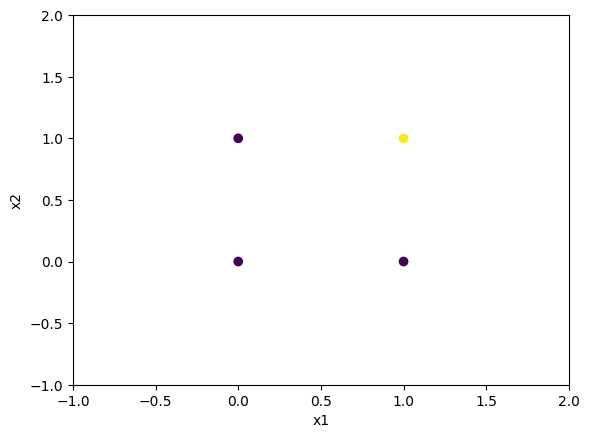

In [3]:
def plot_data(df):
    plt.scatter(df["x1"], df["x2"], c=df["y"])
    plt.xlim(-1, 2)
    plt.ylim(-1, 2)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

# visualizing our toy data
plot_data(AND_data)

In [4]:
class Perceptron:
    def __init__(self, weights) -> None:
        self.weights = weights

    def predict(self, x: np.ndarray) -> np.ndarray:
        return np.sign(x @ self.weights)

In [11]:
manual_weights = np.array([0, -1, 2])  # TODO: fill the array
manual_perceptron = Perceptron(manual_weights)

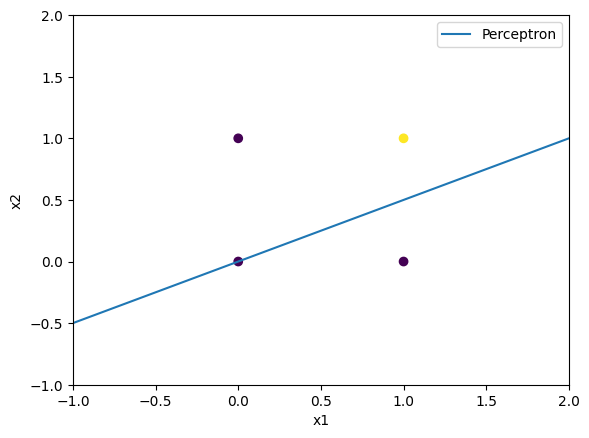

In [12]:
def plot_perceptron_on_data(perceptron, df):
    w = perceptron.weights
    line = np.array([[x1, -(w[0] + w[1] * x1) / w[2]] for x1 in np.linspace(-1, 2, 2)])

    plt.scatter(df["x1"], df["x2"], c=df["y"])
    line_artist = plt.plot(line[:, 0], line[:, 1])[0]
    plt.xlim(-1, 2)
    plt.ylim(-1, 2)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend([line_artist], ["Perceptron"])
    plt.show()


plot_perceptron_on_data(manual_perceptron, AND_data)

> <font color="#e8710a">**📝 Tasks**</font>
>
> 2. Is this a supervised or unsupervised learning problem?
> 3. What is the learning task in this problem called?
> 4. Complete the hypothesis set definition to match your mental model selection process from the first task in this section. (Do it in handwriting if you do not know $\LaTeX$ syntax.)

**✏️ Your answer**

2. Supervised (remove the wrong one)
3. Learning task: Common families --> Unterschiede in den Labeln
4. Hypothesis set:
$$
\mathcal{H} = \{g = A(D) \approx f\}
$$

## Perceptron Learning Algorithm (PLA)

Let's start by implementing the perceptron learning algorithm from the lecture.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 5. Rename the variable `something` to how it is called in the lecture's pseudo code.
> 6. Complete the function implementation.
>     - Use the code cell after that to plot your perceptron and verify your implementation.
> 7. Now you should see a line in that plot. The plot calls it `Perceptron`, but what is this really called?

**✏️ Your answer**

7.

In [ ]:
def PLA(D: pd.DataFrame, label_col="y"):
    if len(D) == 0:
        raise Exception("Training data cannot be empty, but it is.")

    N = len(D)
    d = len(D.columns)-1
    X = np.ones((N, d+1))
    X[:, 1:] = D[D.columns[D.columns != label_col]]
    y = np.array(D[label_col])
    w = np.random.random(d+1)

    while True:
        something = np.sign(X @ w) != y  # TODO: Start by renaming this variable. What is this?
        # TODO: add your code here

    return w

In [ ]:
PLA_weights = PLA(AND_data, label_col)
print("w =", PLA_weights)
PLA_perceptron = Perceptron(PLA_weights)

plot_perceptron_on_data(PLA_perceptron, AND_data)

## Linear Separability

The criterion that tells us whether the PLA can fit a dataset is called linear separability.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 8. Fill in the following mathematical expression where there are underscores, so that it defines linear separability.
> 9. Update point 3 from our previous toy dataset in the following code cell to the closest possible point, such that the data is no longer linearly separable.
> 10. How does your PLA implementation from above behave on this new data?
> 11. Copy your PLA implementation to the function `PLA_robust` below. Now change the breaking condition to avoid this problem. Feel free to change the function signature as you see fit.
> 12. Obtain a perceptron from your function `PLA_robust` for a new dataset by running the last code cell in this section.

**✏️ Your answer**

8. We call a dataset $D = \{(x_n, y_n) \mid x_n \in \_, y_n \in \_\}^N_{n=1}$ linearly separable, iff
$$\exists \_ \in \_ \forall (x_i, y_i) \in D: \_ = y_i.$$

<!-- -->

10.

In [ ]:
not_linearly_separable_data = AND_data.copy()
not_linearly_separable_data.loc[3, "x1"] = 1  # TODO: change value
not_linearly_separable_data.loc[3, "x2"] = 1  # TODO: change value

In [ ]:
plot_data(not_linearly_separable_data)

In [ ]:
def PLA_robust(D: pd.DataFrame, label_col="y"):
    pass  # TODO: implement

In [ ]:
blobs_xs, blobs_ys = make_blobs(100, 2, centers=[[0, 0], [0, 1], [1, 0], [1, 1]], cluster_std=.5)
noisy_AND_data = pd.DataFrame({"x1": blobs_xs[:, 0], "x2": blobs_xs[:, 1], "y": [1 if y == 3 else -1 for y in blobs_ys]})

PLA_robust_weights = PLA_robust(noisy_AND_data, label_col)
print("w =", PLA_robust_weights)
PLA_robust_perceptron = Perceptron(PLA_robust_weights)

plot_perceptron_on_data(PLA_robust_perceptron, noisy_AND_data)

## Confusion Matrix

The confusion matrix is the basis for common classification model evaluation.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 13. Run the following code to obtain a confusion matrix for the perceptron you have just trained.
> 14. Which cell in this matrix relates to which area in this figure: [https://commons.wikimedia.org/wiki/File:Precisionrecall.svg](https://commons.wikimedia.org/wiki/File:Precisionrecall.svg)?

In [ ]:
confmat = confusion_matrix(noisy_AND_data["y"], [PLA_robust_perceptron.predict(np.array([[1, row[0], row[1]]])) for row in noisy_AND_data.itertuples(index=False)])
confmat_display = ConfusionMatrixDisplay(confmat)
confmat_display.plot()
plt.show()

**✏️ Your answer**

14. Relations to Wikipedia figure
    - top-left:
    - top-right:
    - bottom-left:
    - bottom-right:

## Bonus: Elements of learning

Let's look at the final learning setup again, where you applied the `PLA_robust` learning algorithm to the noisy data, and determine the main elements that were involved.

Some questions will be tough to answer. Seek a discussion with fellow student or the class tutor if you feel there is no definitive answer.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 15. Map the definition of a learning algorithm to this setup.
>     1. What is the task T?
>     2. What is the experience E?
>     3. What is the performance measure P?
> 16. Map the elements of the "learning setup diagram" from the lecture to this setup.
>     1. What is the target function?
>     2. What are the training examples?
>     3. What is the hypothesis set?
>     4. What is the learning algorithm?
>     5. What is the final hypothesis?

**✏️ Your answer**

15.
    1.
    2.
    3.

16.
    1.
    2.
    3.
    4.
    5.